# 01 Revisión práctica de Machine Learning

#### Nombre: Kevin Gómez

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.



# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.


In [56]:
# 1. Importar la función desde scikit-learn
from sklearn.datasets import load_iris
import pandas as pd

# 2. Cargar el dataset 
iris = load_iris()

# 3. Ver las claves disponibles en el objeto
print(iris.keys())

# 4. Convertir a un DataFrame de pandas 
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['target'] = iris.target
df['species'] = df['target'].map(
    {i: name for i, name in enumerate(iris.target_names)}
)

# Mostrar las primeras filas
display(df.head())
print(iris.DESCR)

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

### Respuestas

1. **Qué representa cada instancia:** una flor, y cada flor se mide y pertenece a una de las 3 especies.
2. **Número de instancias y características:** 150 instancias y 4 características.
3. **Nombre y significado de cada característica:**
   - `sepal length (cm)`: largo del sépalo.
   - `sepal width (cm)`: ancho del sépalo.
   - `petal length (cm)`: largo del pétalo.
   - `petal width (cm)`: ancho del pétalo.
4. **Clases y cantidad de ejemplos por clase:** 3 `setosa`, `versicolor`, `virginica`, con 50 ejemplos cada una.
5. **Dimensiones de la matriz de características y del vector de etiquetas:** `X` es de 150 filas por 4 columnas, y `y` es un vector de 150 etiquetas.

In [57]:
X, y = iris.data, iris.target
print("Matriz de características X:", X.shape, "| Vector de etiquetas y:", y.shape)
print(df["species"].value_counts())
df.sample(5, random_state=0)

Matriz de características X: (150, 4) | Vector de etiquetas y: (150,)
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
114,5.8,2.8,5.1,2.4,2,virginica
62,6.0,2.2,4.0,1.0,1,versicolor
33,5.5,4.2,1.4,0.2,0,setosa
107,7.3,2.9,6.3,1.8,2,virginica
7,5.0,3.4,1.5,0.2,0,setosa


<Axes: title={'center': 'Distribución de clases en Iris'}, xlabel='species', ylabel='Número de ejemplos'>

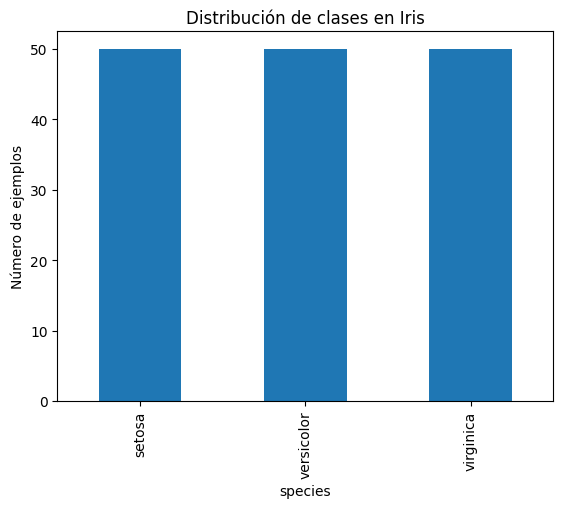

In [58]:
df["species"].value_counts().plot(kind="bar", title="Distribución de clases en Iris", ylabel="Número de ejemplos")

Las tres clases tienen 50 ejemplos, así que el dataset está balanceado.

# 2. Comparación de clasificadores



### Predicciones iniciales

1. **¿Qué modelos crees que serán sensibles a las escalas de las características?:** Regresión logística, SVM lineal y MLP, porque usan pesos y se entrenan con gradientes, y una característica con números grandes pesaría más que las demás, Los árboles, Random Forest y Gradient Boosting solo comparan umbrales, y Naive Bayes ajusta cada característica por separado, así que no deberían afectarse.
2. **¿Qué modelo esperas que produzca fronteras de decisión más simples?:** regresión logística y SVM lineal, porque separan las clases con rectas o planos.
3. **¿Por qué no podemos asegurar de antemano cuál será el mejor?:** depende de cómo estén distribuidos los datos, de la partición y de los hiperparámetros, no se puede tener la certeza de que un modelo funcione perfectamente, ningún modelo gana siempre.

### Procedimiento

Partición 60 % entrenamiento, 20 % validación y 20 % prueba. Todos los modelos usan `StandardScaler` dentro de un pipeline, para que el escalador se ajuste solo con entrenamiento. Cada modelo parte de su configuración inicial la primera de la tabla y se prueban otros valores de un hiperparámetro, elegidos con validación, finalmente la prueba se usa una sola vez al final.

In [59]:
from functools import partial
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

# 60% entrenamiento, 20% validación, 20% prueba, estratificado para conservar las clases
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=42)

In [60]:
clases = {
    "Naive Bayes": GaussianNB,
    "Regresión logística": partial(LogisticRegression, max_iter=1000),
    "SVM lineal": partial(LinearSVC, max_iter=10000),
    "Árbol": partial(DecisionTreeClassifier, random_state=0),
    "Random Forest": partial(RandomForestClassifier, random_state=0),
    "Gradient Boosting": partial(GradientBoostingClassifier, random_state=0),
    "MLP": partial(MLPClassifier, max_iter=2000, random_state=0),
}
# Ajuste limitado: un hiperparámetro por modelo. 
grids = {
    "Regresión logística": ("C", [1, 0.1, 10]),
    "SVM lineal": ("C", [1, 0.1, 10]),
    "Árbol": ("max_depth", [None, 2, 3]),
    "Random Forest": ("n_estimators", [100, 50, 200]),
    "Gradient Boosting": ("learning_rate", [0.1, 0.05, 0.2]),
    "MLP": ("hidden_layer_sizes", [(10,), (5,), (20,)]),
}

def entrenar(nombre, **params):
    return make_pipeline(StandardScaler(), clases[nombre](**params)).fit(X_train, y_train)

def metricas(modelo, X_, y_):
    pred = modelo.predict(X_)
    return accuracy_score(y_, pred), f1_score(y_, pred, average="macro")

# Validación: todas las configuraciones
filas = []
for nombre in clases:
    param, valores = grids.get(nombre, ("", [""]))
    for v in valores:
        acc, f1 = metricas(entrenar(nombre, **({param: v} if param else {})), X_val, y_val)
        filas.append([nombre, param, v, acc, f1])
val = pd.DataFrame(filas, columns=["Modelo", "param", "valor", "Accuracy val", "F1 macro val"])
val.round(3)

,Modelo,param,valor,Accuracy val,F1 macro val
0,Naive Bayes,,,0.933,0.933
1,Regresión logística,C,1,0.933,0.933
2,Regresión logística,C,0.1,0.867,0.865
3,Regresión logística,C,10,0.933,0.933
4,SVM lineal,C,1,0.833,0.833
5,SVM lineal,C,0.1,0.800,0.792
6,SVM lineal,C,10,0.867,0.867
7,Árbol,max_depth,None,0.900,0.900
8,Árbol,max_depth,2,0.900,0.900
9,Árbol,max_depth,3,0.900,0.900


In [61]:
# Se congela la mejor configuración de cada modelo (en empate gana la inicial, que va primero)
mejor = val.loc[val.groupby("Modelo", sort=False)["F1 macro val"].idxmax()]
mejor.round(3)

,Modelo,param,valor,Accuracy val,F1 macro val
0,Naive Bayes,,,0.933,0.933
1,Regresión logística,C,1,0.933,0.933
6,SVM lineal,C,10,0.867,0.867
7,Árbol,max_depth,None,0.900,0.900
10,Random Forest,n_estimators,100,0.933,0.933
13,Gradient Boosting,learning_rate,0.1,0.900,0.900
18,MLP,hidden_layer_sizes,"(20,)",0.933,0.933


In [62]:
# Evaluación final en prueba sin volver a ajustar
filas, preds = [], {}
for r in mejor.itertuples():
    modelo = entrenar(r.Modelo, **({r.param: r.valor} if r.param else {}))
    preds[r.Modelo] = modelo.predict(X_test)
    acc, f1 = metricas(modelo, X_test, y_test)
    filas.append([r.Modelo, "StandardScaler", f"{r.param}={r.valor}" if r.param else "por defecto", acc, f1])
test = pd.DataFrame(filas, columns=["Modelo", "Transformación", "Hiperparámetros principales",
                                    "Accuracy de prueba", "F1 macro de prueba"])
test.round(3)

,Modelo,Transformación,Hiperparámetros principales,Accuracy de prueba,F1 macro de prueba
0,Naive Bayes,StandardScaler,por defecto,0.933,0.933
1,Regresión logística,StandardScaler,C=1,0.933,0.933
2,SVM lineal,StandardScaler,C=10,0.867,0.865
3,Árbol,StandardScaler,max_depth=None,0.967,0.967
4,Random Forest,StandardScaler,n_estimators=100,0.933,0.933
5,Gradient Boosting,StandardScaler,learning_rate=0.1,0.967,0.967
6,MLP,StandardScaler,"hidden_layer_sizes=(20,)",0.967,0.967


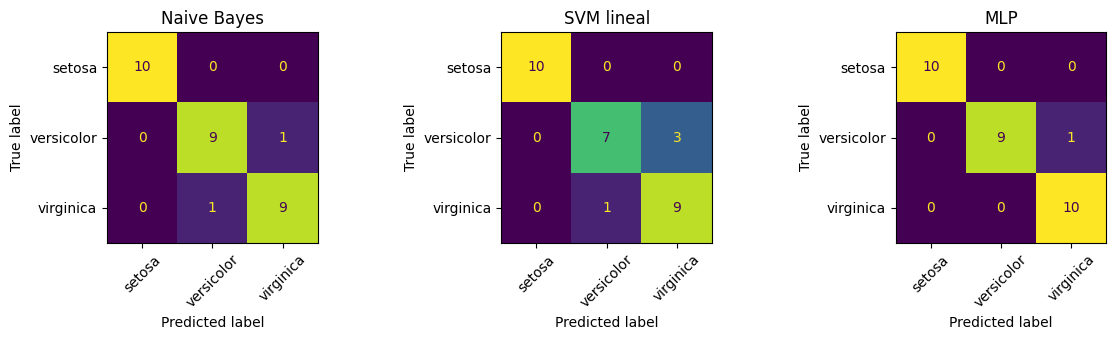

In [63]:
fig, ejes = plt.subplots(1, 3, figsize=(12, 3.5))
for eje, n in zip(ejes, ["Naive Bayes", "SVM lineal", "MLP"]):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[n], display_labels=iris.target_names,
                                            ax=eje, colorbar=False, xticks_rotation=45)
    eje.set_title(n)
plt.tight_layout()

In [64]:
# Los dos ejemplos de prueba que más modelos clasifican mal
fallan = pd.DataFrame({n: p != y_test for n, p in preds.items()}).sum(axis=1)
dificiles = fallan.sort_values(ascending=False, kind="stable").head(2).index
err = pd.DataFrame(X_test[dificiles], columns=iris.feature_names)
err.insert(0, "clase real", iris.target_names[y_test[dificiles]])
err.insert(1, "predicción (reg. logística)", iris.target_names[preds["Regresión logística"][dificiles]])
err.insert(2, "modelos que fallan", fallan[dificiles].values)
display(err)
df.groupby("species")[iris.feature_names].agg(["mean", "std"]).round(2)

,clase real,predicción (reg. logística),modelos que fallan,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,versicolor,virginica,7,6.7,3.0,5.0,1.7
1,virginica,versicolor,4,6.1,2.6,5.6,1.4


sepal length (cm)       sepal width (cm)       petal length (cm)  \
                        mean   std             mean   std              mean   
species                                                                       
setosa                  5.01  0.35             3.43  0.38              1.46   
versicolor              5.94  0.52             2.77  0.31              4.26   
virginica               6.59  0.64             2.97  0.32              5.55   

                 petal width (cm)        
             std             mean   std  
species                                  
setosa      0.17             0.25  0.11  
versicolor  0.47             1.33  0.20  
virginica   0.55             2.03  0.27

### Interpretación

1. **¿Cuál fue el modelo con el mejor desempeño?** Árbol de decisión, Gradient Boosting y MLP quedaron empatados con 0.967 de accuracy y F1 macro (se equivocan en 1 de 30 ejemplos). El peor fue la SVM lineal con 0.867. Esa diferencia es de pocos ejemplos, así que no se puede decir que uno sea claramente mejor. Además el orden cambia respecto a validación, donde el árbol y Gradient Boosting tuvieron 0.90 y el MLP 0.933.
2. **¿Cuál fue el modelo más sencillo de programar?** Gaussian Naive Bayes porque no tiene hiperparámetros que ajustar y basta con `GaussianNB().fit(...)`.
3. **¿Accuracy y F1 macro cuentan la misma historia?** Sí. En todos los modelos salen casi iguales por ejemplo 0.967 y 0.967, o 0.867 y 0.865 en la SVM, porque las tres clases tienen el mismo tamaño y los errores no se concentran en una sola clase.
4. **¿Cuál es la diferencia entre las métricas macro y micro?:** macro calcula la métrica de cada clase y luego promedia, así que todas las clases pesan igual. Micro junta los aciertos y errores de todas las clases y calcula la métrica una sola vez, así que las clases más grandes pesan más. En clasificación multiclase con una sola etiqueta por ejemplo, el F1 micro es igual al accuracy.
5. **¿Qué aporta el MLP frente a un modelo lineal?** Con su capa oculta y su activación no lineal puede aprender fronteras curvas, y su salida pasa por softmax, que convierte los puntajes en probabilidades que suman 1.

### Dos errores de clasificación

**Error 1: flor `versicolor` clasificada como `virginica` por los 7 modelos** (6.7, 3.0, 5.0, 1.7). Sus cuatro medidas están más cerca de la media de virginica que de la de versicolor; por ejemplo, el largo de pétalo 5.0 está a 1.6 desviaciones de versicolor y a 1.0 de virginica.
- *Se puede concluir:* es una flor atípica que se parece más a la clase equivocada, y como la fallan modelos de tipos muy distintos, el problema parece estar en la flor y no en un modelo en particular.
- *No se puede concluir:* cuál característica causó el error, ni que haya un error de medición o de etiqueta. Solo vemos que sus valores se parecen a los de virginica.

**Error 2: flor `virginica` clasificada como `versicolor` por 4 modelos** (6.1, 2.6, 5.6, 1.4). El ancho de pétalo (1.4) es muy bajo para virginica a 2.3 desviaciones de su media y el ancho y largo de sépalo también quedan más cerca de versicolor. En cambio, el largo de pétalo (5.6) es típico de virginica.
- *Se puede concluir:* tiene medidas mezcladas, en la zona donde se solapan las dos especies. Los otros 3 modelos (árbol, Gradient Boosting y MLP) sí la acertaron.
- *No se puede concluir:* que esos 3 modelos sean mejores en general es (una sola flor), ni cuál es la causa real del error.

# 3. Comparación de modelos de regresión

## Dataset: Diabetes



### Predicción inicial

No, un modelo más flexible no siempre da menor error en datos nuevos. Ajusta mejor el entrenamiento, pero puede aprender el ruido sobreajuste y fallar con datos que no vio. Con solo 442 pacientes y un objetivo ruidoso, espero que los modelos simples rindan casi igual que los complejos.

### Procedimiento

Misma idea que antes: partición 60/20/20, `StandardScaler` dentro de pipelines, un hiperparámetro por modelo elegido con el RMSE de validación, y prueba solo al final. 

In [65]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

diab = load_diabetes()
print(diab.DESCR)
Xd, yd = diab.data, diab.target
print("X:", Xd.shape, "| y:", yd.shape)
print("Suma de cuadrados de cada columna:", (Xd ** 2).sum(axis=0).round(2))

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

In [66]:
Xd_tmp, Xd_test, yd_tmp, yd_test = train_test_split(Xd, yd, test_size=0.2, random_state=42)
Xd_train, Xd_val, yd_train, yd_val = train_test_split(Xd_tmp, yd_tmp, test_size=0.25, random_state=42)

rmse = lambda real, pred: np.sqrt(mean_squared_error(real, pred))
def metricas_r(real, pred):
    return mean_absolute_error(real, pred), rmse(real, pred), r2_score(real, pred)

clases_r = {
    "Regresión lineal": LinearRegression,
    "Ridge": Ridge,
    "Lasso": partial(Lasso, max_iter=10000),
    "kNN": KNeighborsRegressor,
    "Árbol": partial(DecisionTreeRegressor, random_state=0),
    "Random Forest": partial(RandomForestRegressor, random_state=0),
    "Gradient Boosting": partial(GradientBoostingRegressor, random_state=0),
    "MLP": partial(MLPRegressor, max_iter=3000, random_state=0),
}
# Ajuste limitado con validación (el primer valor es la configuración inicial)
grids_r = {
    "Ridge": ("alpha", [1, 0.1, 10, 100]),
    "Lasso": ("alpha", [1, 0.1, 10]),
    "kNN": ("n_neighbors", [5, 10, 20]),
    "Árbol": ("max_depth", [None, 3, 5]),
    "Random Forest": ("min_samples_leaf", [1, 5, 10]),
    "Gradient Boosting": ("learning_rate", [0.1, 0.05]),
    "MLP": ("alpha", [0.0001, 0.1, 1.0]),
}

def entrenar_r(nombre, **params):
    modelo = make_pipeline(StandardScaler(), clases_r[nombre](**params))
    if nombre == "MLP":  # el objetivo se estandariza con entrenamiento y las predicciones vuelven a la escala original
        modelo = TransformedTargetRegressor(regressor=modelo, transformer=StandardScaler())
    return modelo.fit(Xd_train, yd_train)

filas = []
for nombre in clases_r:
    param, valores = grids_r.get(nombre, ("", [""]))
    for v in valores:
        m = entrenar_r(nombre, **({param: v} if param else {}))
        filas.append([nombre, param, v, *metricas_r(yd_val, m.predict(Xd_val))])
val_r = pd.DataFrame(filas, columns=["Modelo", "param", "valor", "MAE val", "RMSE val", "R² val"])
val_r.round(2)

,Modelo,param,valor,MAE val,RMSE val,R² val
0,Regresión lineal,,,42.94,51.19,0.52
1,Ridge,alpha,1,42.72,51.10,0.52
2,Ridge,alpha,0.1,42.91,51.17,0.52
3,Ridge,alpha,10,42.62,51.16,0.52
4,Ridge,alpha,100,43.43,51.74,0.51
5,Lasso,alpha,1,42.47,51.06,0.52
6,Lasso,alpha,0.1,42.64,51.10,0.52
7,Lasso,alpha,10,45.14,53.15,0.48
8,kNN,n_neighbors,5,45.29,56.83,0.41
9,kNN,n_neighbors,10,43.86,54.64,0.46


In [67]:
mejor_r = val_r.loc[val_r.groupby("Modelo", sort=False)["RMSE val"].idxmin()]
display(mejor_r.round(2))

# Evaluación final en prueba
filas, finales, pred_r = [], {}, {}
for r in mejor_r.itertuples():
    finales[r.Modelo] = entrenar_r(r.Modelo, **({r.param: r.valor} if r.param else {}))
    pred_r[r.Modelo] = finales[r.Modelo].predict(Xd_test)
    filas.append([r.Modelo, *metricas_r(yd_test, pred_r[r.Modelo])])
test_r = pd.DataFrame(filas, columns=["Modelo", "MAE", "RMSE", "R²"])
test_r.round(3)

,Modelo,param,valor,MAE val,RMSE val,R² val
0,Regresión lineal,,,42.94,51.19,0.52
1,Ridge,alpha,1,42.72,51.10,0.52
5,Lasso,alpha,1,42.47,51.06,0.52
10,kNN,n_neighbors,20,45.56,54.55,0.46
12,Árbol,max_depth,3,46.57,58.23,0.38
15,Random Forest,min_samples_leaf,5,43.37,53.64,0.47
17,Gradient Boosting,learning_rate,0.1,44.48,53.74,0.47
21,MLP,alpha,1.0,42.66,53.46,0.48


,Modelo,MAE,RMSE,R²
0,Regresión lineal,42.924,54.156,0.446
1,Ridge,42.970,54.031,0.449
2,Lasso,42.722,53.302,0.464
3,kNN,45.893,55.860,0.411
4,Árbol,47.076,60.248,0.315
5,Random Forest,43.803,53.852,0.453
6,Gradient Boosting,44.562,54.777,0.434
7,MLP,40.122,51.397,0.501


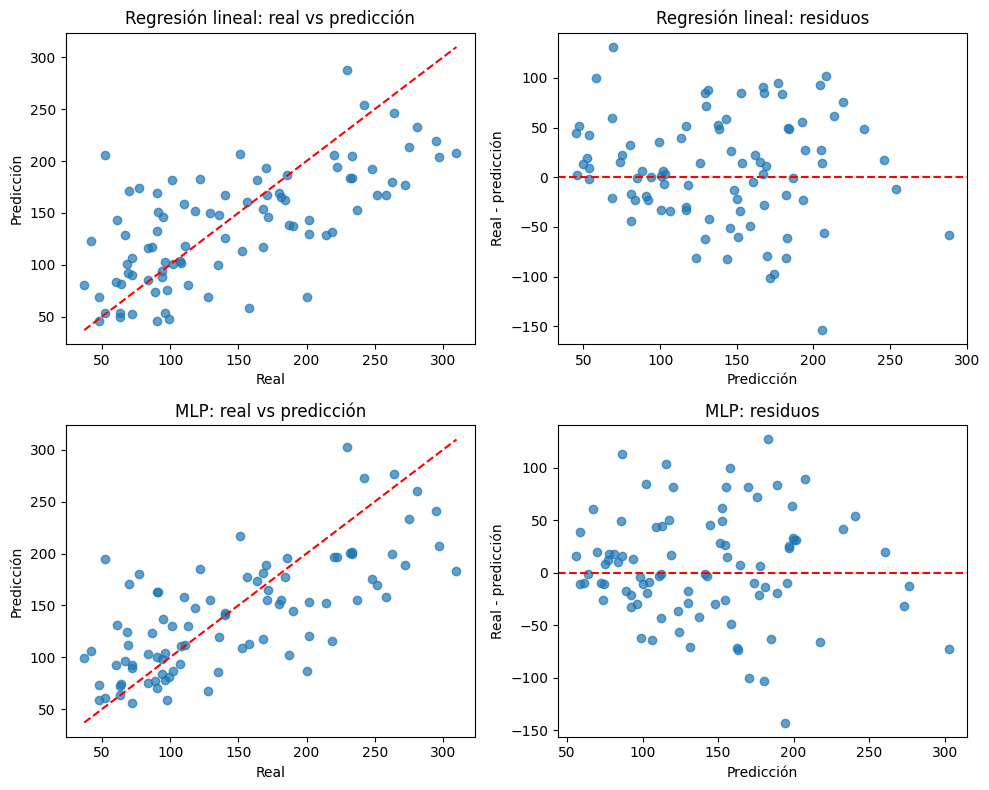

In [68]:
fig, ejes = plt.subplots(2, 2, figsize=(10, 8))
for fila, n in enumerate(["Regresión lineal", "MLP"]):
    p = pred_r[n]
    ejes[fila, 0].scatter(yd_test, p, alpha=0.7)
    ejes[fila, 0].plot([yd_test.min(), yd_test.max()], [yd_test.min(), yd_test.max()], "r--")
    ejes[fila, 0].set(title=f"{n}: real vs predicción", xlabel="Real", ylabel="Predicción")
    ejes[fila, 1].scatter(p, yd_test - p, alpha=0.7)
    ejes[fila, 1].axhline(0, color="r", linestyle="--")
    ejes[fila, 1].set(title=f"{n}: residuos", xlabel="Predicción", ylabel="Real - predicción")
plt.tight_layout()

In [69]:
# Dos ejemplos de prueba con mayor error absoluto en cada modelo
filas = []
for n in ["Regresión lineal", "MLP"]:
    error = np.abs(yd_test - pred_r[n])
    for i in np.argsort(error)[::-1][:2]:
        filas.append([n, i, yd_test[i], pred_r[n][i], error[i]])
pd.DataFrame(filas, columns=["Modelo", "Ejemplo de prueba", "Real", "Predicción", "|Error|"]).round(1)

,Modelo,Ejemplo de prueba,Real,Predicción,|Error|
0,Regresión lineal,61,52.0,205.7,153.7
1,Regresión lineal,46,200.0,69.0,131.0
2,MLP,61,52.0,194.5,142.5
3,MLP,20,310.0,182.9,127.1


In [70]:
# Ridge y Lasso con distintas intensidades de penalización
filas = []
for nombre, clase, alphas in [("Ridge", Ridge, [0.01, 0.1, 1, 10, 100, 1000]),
                              ("Lasso", clases_r["Lasso"], [0.01, 0.1, 1, 3, 10, 30, 100])]:
    for a in alphas:
        m = make_pipeline(StandardScaler(), clase(alpha=a)).fit(Xd_train, yd_train)
        c = m[-1].coef_
        filas.append([nombre, a, np.abs(c).max(), (c == 0).sum(),
                      rmse(yd_train, m.predict(Xd_train)), rmse(yd_val, m.predict(Xd_val))])
pd.DataFrame(filas, columns=["Modelo", "alpha", "Máx |coef|", "Coef. nulos", "RMSE train", "RMSE val"]).round(2)

,Modelo,alpha,Máx |coef|,Coef. nulos,RMSE train,RMSE val
0,Ridge,0.01,50.87,0,54.61,51.19
1,Ridge,0.10,48.92,0,54.61,51.17
2,Ridge,1.00,35.69,0,54.64,51.10
3,Ridge,10.00,25.06,0,54.84,51.16
4,Ridge,100.00,20.16,0,55.86,51.74
5,Ridge,1000.00,7.62,0,65.42,60.60
6,Lasso,0.01,49.35,0,54.61,51.18
7,Lasso,0.10,33.57,0,54.65,51.10
8,Lasso,1.00,25.66,1,54.91,51.06
9,Lasso,3.00,25.34,3,55.51,51.04


In [71]:
# R² negativo: peor que predecir siempre la media de entrenamiento
print("R² prediciendo siempre la media de entrenamiento:", round(r2_score(yd_test, np.full(len(yd_test), yd_train.mean())), 3))
print("R² prediciendo siempre 300:", round(r2_score(yd_test, np.full(len(yd_test), 300.0)), 3))

R² prediciendo siempre la media de entrenamiento: -0.003
R² prediciendo siempre 300: -4.489


### Interpretación

1. **¿Qué modelo tuvo el mejor desempeño?** En prueba, el MLP fue el mejor en las tres métricas (MAE 40.1, RMSE 51.4, R² 0.50). Pero en validación los mejores fueron los modelos lineales (RMSE 51.1) y el MLP quedó con 53.5, así que el ranking cambia. Las diferencias son chicas (con 89 ejemplos de prueba) y el mejor R² es apenas 0.50, así que hay mucho ruido que las 10 variables no explican.
2. **¿Por qué MAE y RMSE pueden favorecer resultados diferentes?:** el MAE promedia los errores en valor absoluto, así que todos pesan igual. El RMSE los eleva al cuadrado, así que castiga mucho más los errores grandes.
3. **¿Cómo se interpreta un R² negativo?:** significa que el modelo predice peor que uno que siempre devuelve la media de entrenamiento.
4. **¿Qué efecto tuvo aumentar la regularización?:**
   - *Ridge:* los coeficientes se encogen (el máximo baja de 50.9 a 7.6) pero ninguno llega a cero. El error de entrenamiento siempre sube (54.6 a 65.4). El de validación mejora muy poco hasta alpha = 1 (51.1) y después empeora, hasta 60.6 con alpha = 1000.
   - *Lasso:* además de encoger, anula coeficientes: de 0 con alpha = 0.01 a los 10 con alpha = 100. Con alpha = 100 el modelo solo predice la media y el error es el peor (RMSE de validación 75.6).
   - En ambos, un poco de regularización mejora muy poco la validación y demasiada la empeora (subajuste). En el MLP, subir `alpha` de 0.0001 a 1 sí ayudó mucho (R² de validación de 0.05 a 0.48), porque con poca regularización sobreajustaba.
5. **¿Qué puede explicar los errores grandes?:** el paciente con mayor error es el mismo en la regresión lineal y en el MLP (real = 52, predicho 205.7 y 194.5). Que dos modelos distintos fallen igual sugiere que la causa está en los datos: ruido natural de la enfermedad o variables que no están en el dataset. En los gráficos también se ve que los modelos sobreestiman los valores bajos y subestiman los altos (por ejemplo, real = 310 con predicción de 183). Con estos casos no se puede saber la causa exacta.
6. **¿Un coeficiente predictivo demuestra causalidad?** No. Solo muestra una asociación útil para predecir, dadas las demás variables del modelo. Puede haber variables correlacionadas entre sí (como `s1` y `s2`), factores sin medir, y el valor cambia con la regularización. Que `bmi` tenga un coeficiente alto no prueba que el IMC cause más progresión.